# 🎲 Simulación del Juego Yahtzee con Método de Montecarlo
---
### 📌 1. Fundamento Teórico y Distribución de Probabilidad
- **Distribución Uniforme Discreta:** Cada dado posee 6 caras equiprobables. La probabilidad de obtener cualquier valor $k \in \{1, 2, 3, 4, 5, 6\}$ es:
  $$P(X = k) = \frac{1}{6} \approx 16.67\%$$
- **Método de Montecarlo:** Se generan números pseudoaleatorios para simular múltiples tiradas de dados y modelar el comportamiento del juego, estimando empíricamente probabilidades de combinaciones complejas.
- **Relación con Procesos de Markov:** En cada turno existen hasta 3 lanzamientos. La transición de un estado (dados conservados) al siguiente depende únicamente del estado actual y del resultado aleatorio de los dados relanzados.

In [ ]:
# 1. Importación de librerías
import random
import matplotlib.pyplot as plt

print('Librerías importadas correctamente.')

Librerías importadas correctamente.


### 🎲 2. Funciones de Simulación de Dados y Puntuaciones
Se implementa el lanzamiento de dados con distribución uniforme y las reglas clásicas de puntuación de Yahtzee.

In [ ]:
def lanzar_dados(cantidad):
    """Simula el lanzamiento de dados usando distribución uniforme entre 1 y 6."""
    return [random.randint(1, 6) for _ in range(cantidad)]

def calcular_puntos(categoria, dados):
    """Calcula los puntos que otorgan los dados según la categoría elegida."""
    conteo = {x: dados.count(x) for x in range(1, 7)}
    unicos = sorted(set(dados))

    # Sección Superior
    if categoria == "Unos":
        return dados.count(1) * 1
    elif categoria == "Doses":
        return dados.count(2) * 2
    elif categoria == "Treses":
        return dados.count(3) * 3
    elif categoria == "Cuatros":
        return dados.count(4) * 4
    elif categoria == "Cincos":
        return dados.count(5) * 5
    elif categoria == "Seises":
        return dados.count(6) * 6

    # Sección Inferior
    elif categoria == "Trío":
        return sum(dados) if any(c >= 3 for c in conteo.values()) else 0

    elif categoria == "Cuarteto":
        return sum(dados) if any(c >= 4 for c in conteo.values()) else 0

    elif categoria == "Full House":
        vals = sorted(conteo.values(), reverse=True)
        if (vals[0] == 3 and vals[1] == 2) or (vals[0] == 5):
            return 25
        return 0

    elif categoria == "Escalera Menor":
        secuencias = [{1, 2, 3, 4}, {2, 3, 4, 5}, {3, 4, 5, 6}]
        set_dados = set(dados)
        return 30 if any(sec.issubset(set_dados) for sec in secuencias) else 0

    elif categoria == "Escalera Mayor":
        return 40 if unicos in [[1, 2, 3, 4, 5], [2, 3, 4, 5, 6]] else 0

    elif categoria == "Yahtzee":
        return 50 if any(c == 5 for c in conteo.values()) else 0

    elif categoria == "Chance":
        return sum(dados)

    return 0

print('Funciones de dados y reglas de puntuación definidas.')

Funciones de dados y reglas de puntuación definidas.


### 📊 3. Experimento de Montecarlo: Análisis y Gráficos Estadísticos
Simulamos 10,000 tiradas para explotar los resultados aleatorios obtenidos, verificar la distribución uniforme y calcular probabilidades de las jugadas.

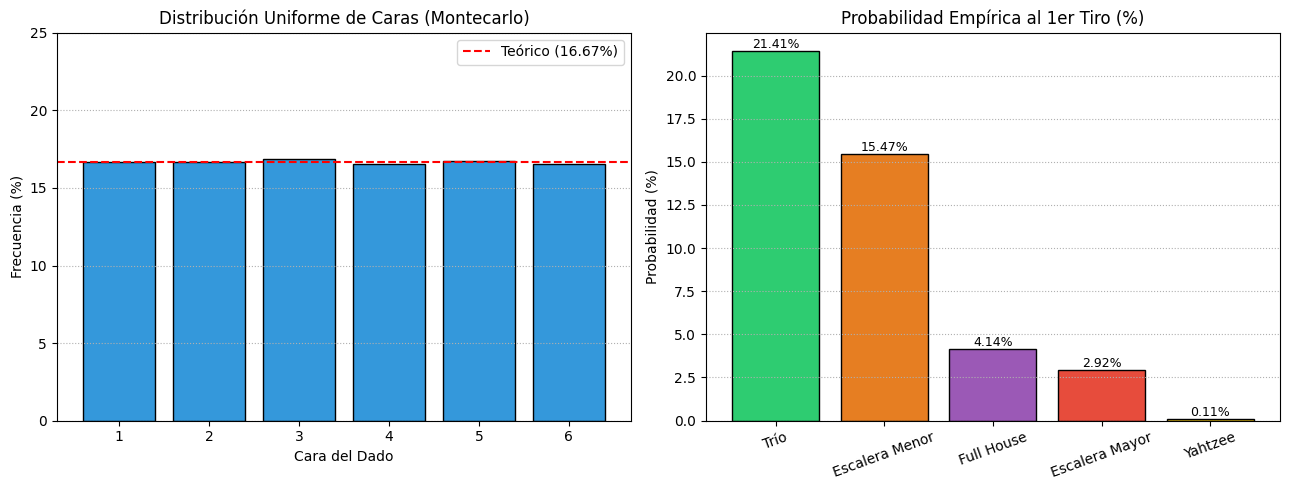

--- RESULTADOS NUMÉRICOS MONTECARLO ---
Trío            :  2141 aciertos de 10000 (21.410%)
Escalera Menor  :  1547 aciertos de 10000 (15.470%)
Full House      :   414 aciertos de 10000 (4.140%)
Escalera Mayor  :   292 aciertos de 10000 (2.920%)
Yahtzee         :    11 aciertos de 10000 (0.110%)


In [ ]:
n_simulaciones = 10000
frecuencia_caras = {i: 0 for i in range(1, 7)}
conteo_combinaciones = {
    'Trío': 0,
    'Escalera Menor': 0,
    'Full House': 0,
    'Escalera Mayor': 0,
    'Yahtzee': 0
}

for _ in range(n_simulaciones):
    dados = lanzar_dados(5)
    for d in dados:
        frecuencia_caras[d] += 1

    if calcular_puntos('Trío', dados) > 0:
        conteo_combinaciones['Trío'] += 1
    if calcular_puntos('Escalera Menor', dados) == 30:
        conteo_combinaciones['Escalera Menor'] += 1
    if calcular_puntos('Full House', dados) == 25:
        conteo_combinaciones['Full House'] += 1
    if calcular_puntos('Escalera Mayor', dados) == 40:
        conteo_combinaciones['Escalera Mayor'] += 1
    if calcular_puntos('Yahtzee', dados) == 50:
        conteo_combinaciones['Yahtzee'] += 1

# Graficar distribución uniforme y probabilidades
total_dados = n_simulaciones * 5
caras = list(frecuencia_caras.keys())
porcentajes_caras = [(frecuencia_caras[c] / total_dados) * 100 for c in caras]

plt.figure(figsize=(13, 5))

# Gráfico 1: Caras de dados
plt.subplot(1, 2, 1)
plt.bar(caras, porcentajes_caras, color='#3498db', edgecolor='black')
plt.axhline(y=16.67, color='red', linestyle='--', label='Teórico (16.67%)')
plt.title('Distribución Uniforme de Caras (Montecarlo)')
plt.xlabel('Cara del Dado')
plt.ylabel('Frecuencia (%)')
plt.ylim(0, 25)
plt.legend()
plt.grid(axis='y', linestyle=':')

# Gráfico 2: Combinaciones
plt.subplot(1, 2, 2)
cats = list(conteo_combinaciones.keys())
pct_comb = [(conteo_combinaciones[c] / n_simulaciones) * 100 for c in cats]
colores = ['#2ecc71', '#e67e22', '#9b59b6', '#e74c3c', '#f1c40f']
barras = plt.bar(cats, pct_comb, color=colores, edgecolor='black')
plt.title('Probabilidad Empírica al 1er Tiro (%)')
plt.xticks(rotation=20)
plt.ylabel('Probabilidad (%)')
for b in barras:
    h = b.get_height()
    plt.annotate(f'{h:.2f}%', (b.get_x() + b.get_width() / 2, h),
                 ha='center', va='bottom', fontsize=9)
plt.grid(axis='y', linestyle=':')

plt.tight_layout()
plt.show()

print('--- RESULTADOS NUMÉRICOS MONTECARLO ---')
for c, cnt in conteo_combinaciones.items():
    pct = (cnt / n_simulaciones) * 100
    print(f'{c:16}: {cnt:5d} aciertos de {n_simulaciones} ({pct:.3f}%)')

### 👥 4. Funciones de Juego para 2 Jugadores
Manejo de turnos con hasta 3 tiradas (conservando dados deseados), selección de categorías y actualización de marcadores.

In [ ]:
def crear_tablero():
    return {
        'Unos': None, 'Doses': None, 'Treses': None,
        'Cuatros': None, 'Cincos': None, 'Seises': None,
        'Trío': None, 'Cuarteto': None, 'Full House': None,
        'Escalera Menor': None, 'Escalera Mayor': None,
        'Yahtzee': None, 'Chance': None
    }

def mostrar_marcador(nombre1, tablero1, nombre2, tablero2):
    print('\n' + '=' * 55)
    print(f'{"MARCADOR DE LA PARTIDA":^55}')
    print('=' * 55)
    print(f'{"Categoría":<18} | {nombre1:<15} | {nombre2:<15}')
    print('-' * 55)
    for cat in tablero1:
        v1 = tablero1[cat] if tablero1[cat] is not None else '-'
        v2 = tablero2[cat] if tablero2[cat] is not None else '-'
        print(f'{cat:<18} | {str(v1):<15} | {str(v2):<15}')

    t1 = sum(v for v in tablero1.values() if v is not None)
    t2 = sum(v for v in tablero2.values() if v is not None)
    print('-' * 55)
    print(f'{"TOTAL PUNTOS":<18} | {t1:<15} | {t2:<15}')
    print('=' * 55)

def turno_jugador(nombre, tablero):
    print(f'\n👉 TURNO DE: {nombre}')
    dados = lanzar_dados(5)
    print(f'  Lanzamiento 1: {dados}')

    # Hasta 2 relanzamientos adicionales
    for l in range(2, 4):
        resp = input('  ¿Deseas relanzar dados? (s/n): ').strip().lower()
        if resp != 's':
            break
        pos = input('  Posiciones a cambiar (1 a 5 separadas por espacio, ej: 1 3): ')
        indices = [int(p) - 1 for p in pos.split() if p.isdigit()]
        for idx in indices:
            if 0 <= idx < 5:
                dados[idx] = random.randint(1, 6)
        print(f'  Lanzamiento {l}: {dados}')

    print(f'\n  Dados finales de {nombre}: {dados}')

    libres = [c for c, v in tablero.items() if v is None]
    print('  Categorías disponibles:')
    for i, c in enumerate(libres, 1):
        pts = calcular_puntos(c, dados)
        print(f'    [{i}] {c:<16} (obtendrías {pts} pts)')

    while True:
        opc = input(f'  {nombre}, escribe el número de la categoría elegida: ').strip()
        if opc.isdigit() and 1 <= int(opc) <= len(libres):
            cat_sel = libres[int(opc) - 1]
            ganados = calcular_puntos(cat_sel, dados)
            tablero[cat_sel] = ganados
            print(f'  ✔️ ¡Anotaste {ganados} puntos en {cat_sel}!')
            break
        print('  ⚠️ Opción no válida. Intenta de nuevo.')

print('Lógica de turnos y marcadores lista.')

Lógica de turnos y marcadores lista.


### 🎮 5. Iniciar la Partida entre 2 Jugadores
Ejecuta la siguiente celda para jugar. Puedes seleccionar cuántas rondas jugar (por defecto 13 rondas, o elegir 3 para una partida rápida de prueba).

In [ ]:
def jugar():
    print('🎲 INICIO DEL JUEGO YAHTZEE (2 JUGADORES) 🎲')
    j1 = input('Nombre Jugador 1: ').strip() or 'Jugador 1'
    j2 = input('Nombre Jugador 2: ').strip() or 'Jugador 2'

    r_inp = input('¿Cuántas rondas jugar? (1-13, Enter para 13 completa): ').strip()
    rondas = int(r_inp) if r_inp.isdigit() and 1 <= int(r_inp) <= 13 else 13

    tab1 = crear_tablero()
    tab2 = crear_tablero()

    for r in range(1, rondas + 1):
        print(f'\n{"*" * 55}')
        print(f'{" RONDA " + str(r) + " DE " + str(rondas) + " ":^55}')
        print('*' * 55)
        turno_jugador(j1, tab1)
        turno_jugador(j2, tab2)
        mostrar_marcador(j1, tab1, j2, tab2)

    # Marcador final
    tot1 = sum(v for v in tab1.values() if v is not None)
    tot2 = sum(v for v in tab2.values() if v is not None)
    print('\n🏆 ¡FINAL DE LA PARTIDA! 🏆')
    mostrar_marcador(j1, tab1, j2, tab2)
    if tot1 > tot2:
        print(f'🎉 ¡Ganador: {j1} con {tot1} puntos!')
    elif tot2 > tot1:
        print(f'🎉 ¡Ganador: {j2} con {tot2} puntos!')
    else:
        print(f'🤝 ¡Empate con {tot1} puntos!')

# Llamar al juego
jugar()

🎲 INICIO DEL JUEGO YAHTZEE (2 JUGADORES) 🎲

*******************************************************
                     RONDA 1 DE 1                      
*******************************************************

👉 TURNO DE: david
  Lanzamiento 1: [6, 6, 3, 5, 2]
  Lanzamiento 2: [3, 6, 3, 5, 2]
  Lanzamiento 3: [3, 6, 3, 5, 2]

  Dados finales de david: [3, 6, 3, 5, 2]
  Categorías disponibles:
    [1] Unos             (obtendrías 0 pts)
    [2] Doses            (obtendrías 2 pts)
    [3] Treses           (obtendrías 6 pts)
    [4] Cuatros          (obtendrías 0 pts)
    [5] Cincos           (obtendrías 5 pts)
    [6] Seises           (obtendrías 6 pts)
    [7] Trío             (obtendrías 0 pts)
    [8] Cuarteto         (obtendrías 0 pts)
    [9] Full House       (obtendrías 0 pts)
    [10] Escalera Menor   (obtendrías 0 pts)
    [11] Escalera Mayor   (obtendrías 0 pts)
    [12] Yahtzee          (obtendrías 0 pts)
    [13] Chance           (obtendrías 19 pts)
  ✔️ ¡Anotaste 0 puntos 